# RanPAC · Algorithm 1 trên Split CIFAR-100

Triển khai cả hai phase của RanPAC bằng PyTorch. Dùng ViT-B/16 với trọng số AugReg ImageNet-21K, seed 1993 và 10 task có 10 lớp mới mỗi task.

1. **First-session PETL.** Gắn AdaptFormer vào 12 block ViT. Với trạng thái token \(x\) sau attention, cộng nhánh \(0.1\,W_{\rm up}\operatorname{Dropout}(\operatorname{ReLU}(W_{\rm down}x+b_{\rm down}))+0.1\,b_{\rm up}\) song song với FFN. Train adapter và head tạm 10 lớp trên ảnh train của task 1 bằng cross-entropy.
2. **Continual learning.** Bỏ head tạm, đóng băng cả ViT và adapter. Tạo \(W\sim\mathcal{N}(0,1)^{768\times M}\) một lần. Từ task 1, dùng embedding đã thích nghi \(F_t\) để tính \(H_t=\operatorname{ReLU}(F_t W)\), rồi cộng \(H_t^\top H_t\) vào \(G\) và \(H_t^\top Y_t\) vào \(C\). Chọn \(\lambda_t\) từ tập train task hiện tại và giải \((G+\lambda_t I)B_t=C\). Dự đoán bằng \(H B_t\) trên toàn bộ lớp đã thấy, với ID task chỉ dùng để tính \(R[t,i]\).

Mã AdaptFormer và vòng lặp hai phase nằm trong [ranpac_full.py](ranpac_full.py). Phần ridge dùng lại [ranpac_core.py](ranpac_core.py) của các notebook ablation. [Algorithm 1 và Appendix C](https://papers.nips.cc/paper_files/paper/2023/file/2793dc35e14003dd367684d93d236847-Paper-Conference.pdf#page=8)

## 1. Chuẩn bị Colab

Chọn **Runtime → Change runtime type → GPU**. Đặt `ranpac_full.py`, `ranpac_core.py`, `ranpac_data.py`, `ranpac_colab.py` và `test_ranpac_core.py` trong `MyDrive/RanPAC_implement`. Nếu mã ở vị trí khác, sửa `SOURCE_DIR`. CIFAR-100 và trọng số pretrained được tải ở lần chạy cần dùng.

Chế độ W&B `online` dùng `WANDB_API_KEY` trong Colab Secrets và cần quyền ghi vào `WANDB_ENTITY/WANDB_PROJECT`. Chọn `disabled` để chỉ lưu kết quả trên Drive hoặc `offline` để lưu log W&B trên Drive và sync sau.

In [ ]:
%pip install -q timm==1.0.22 wandb==0.31.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [ ]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount('/content/drive')
SOURCE_DIR = Path('/content/drive/MyDrive/RanPAC_implement')
WORK_DIR = Path('/content/drive/MyDrive/ranpac-runs')

required = ('ranpac_full.py', 'ranpac_core.py', 'ranpac_data.py', 'ranpac_colab.py', 'test_ranpac_core.py')
missing = [name for name in required if not (SOURCE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Thiếu {", ".join(missing)} trong {SOURCE_DIR}')
sys.path.insert(0, str(SOURCE_DIR))

from ranpac_full import run_algorithm1

Mounted at /content/drive


## 2. Cấu hình thí nghiệm

Mặc định dùng **20 epoch Phase 1, batch 48, FP32, `M=10000` và chọn λ theo task**. SGD dùng learning rate 0.01, momentum 0.9, weight decay 0.0005 và cosine annealing về 0. Task 1 dùng random resized crop và horizontal flip khi train. Phase 2 dùng resize bicubic, center crop và `ToTensor` cho cả train và test, với tùy chọn chuẩn hóa ảnh tắt như cấu hình CIFAR-100 của tác giả. [Appendix C](https://papers.nips.cc/paper_files/paper/2023/file/2793dc35e14003dd367684d93d236847-Paper-Conference.pdf#page=20) · [Cấu hình CIFAR-100 ID 7](https://github.com/McDonnell-Research-Lab/RanPAC/blob/main/args/cifar224_publish.csv#L9) · [Transforms gốc](https://github.com/McDonnell-Research-Lab/RanPAC/blob/main/utils/data.py#L16)

| Hạng mục | Paper hoặc repo tác giả | Triển khai này và lý do |
| --- | --- | --- |
| Head tạm | Paper mô tả head tuyến tính. Repo CIFAR-100 dùng cosine với scale học được. | Mặc định `cosine` để gần cấu hình công bố. Chọn `linear` để thử head affine theo mô tả trong paper. Cả hai dùng cross-entropy và head được bỏ sau Phase 1. |
| Chọn λ | Repo dùng 80/20 theo thứ tự loader đã shuffle của task hiện tại, chấm bằng MSE trên lưới từ \(10^{-8}\) đến \(10^8\), giải ridge riêng cho từng λ. | Giữ lưới và MSE, tạo split tái lập bằng seed theo task như notebook 03. Khi số chiều lớn hơn số mẫu fit, dùng dạng dual với một phân rã trị riêng để dùng chung cho cả lưới. Head cuối được giải bằng `solve` trên thống kê tích lũy của tất cả mẫu train đã thấy. |
| ViT và RP | Repo dùng timm 0.6.12 với ViT AdaptFormer riêng. Ma trận RP lấy mẫu Gaussian qua RNG của run. | Dùng ViT timm 1.0.22 với cùng checkpoint AugReg và tự thêm nhánh adapter ở từng block. Dùng RNG riêng cho RP để có cùng ma trận với notebook 03 khi giữ seed và `M`. |
| Bộ nhớ Phase 1 | Cấu hình công bố dùng batch 48. | Giữ FP32 và batch 48 mặc định. Nếu thiếu VRAM, thử `MICROBATCH=24` hoặc `16`, tích lũy gradient để mỗi bước SGD vẫn dùng tối đa 48 ảnh. `PRECISION='amp-fp16'` giảm bộ nhớ activations và có thể làm thay đổi kết quả số. |
| Chi phí Phase 2 | Table 1 dùng `M=10000` và chọn λ theo task. Table A5 khảo sát `M` nhỏ hơn với λ=100, bỏ Phase 1. | Có thể giảm `M` xuống 2500 với λ vẫn chọn theo task để thử tác động của số chiều. Đặt thêm `FIXED_LAMBDA=100.0` để bỏ bước tìm λ khi smoke test. Recipe có PETL và `M=2500` là một cấu hình thử riêng. |
| Số epoch và chọn model | Repo CIFAR-100 train 20 epoch và tính test accuracy task 1 mỗi epoch. | Giữ 20 epoch và dùng trạng thái cuối. Phase 1 chỉ log train loss và accuracy, đánh giá test bắt đầu ở Phase 2. Có thể dùng `PHASE1_EPOCHS=2` cho pilot độc lập. Thay đổi này cũng rút ngắn lịch cosine. |

[Mã head và lựa chọn AdaptFormer của tác giả](https://github.com/McDonnell-Research-Lab/RanPAC/blob/main/inc_net.py) · [Cách chọn λ của tác giả](https://github.com/McDonnell-Research-Lab/RanPAC/blob/main/RanPAC.py#L127) · [Table A5](https://papers.nips.cc/paper_files/paper/2023/file/2793dc35e14003dd367684d93d236847-Paper-Conference.pdf#page=28)

In [ ]:
RUN_LABEL = 'main'
RESUME = False

PHASE1_EPOCHS = 20
STOP_AFTER_EPOCH = None  # None runs to PHASE1_EPOCHS and then starts Phase 2.
STOP_AFTER_TASK = 10    # Set to 2 for a shorter pilot.
MICROBATCH = 48
PRECISION = 'fp32'     # 'fp32' or 'amp-fp16' for Phase 1 only.
TEMPORARY_HEAD = 'cosine'

M = 10_000
FIXED_LAMBDA = None    # None selects lambda on an 80/20 split per task.
FEATURE_BATCH_SIZE = 48
STATS_DEVICE = 'cpu'
NUM_WORKERS = 2

WANDB_ENTITY = 'pnp123'
WANDB_PROJECT = 'ML'
WANDB_MODE = 'online'  # 'online', 'offline', or 'disabled'.

## 3. Chạy hoặc tiếp tục

- **Đo chi phí Phase 1.** Đặt `STOP_AFTER_EPOCH=2` để lưu checkpoint sau epoch 2 và tạm dừng. Lần sau đặt `RESUME=True` và `STOP_AFTER_EPOCH=None` để tiếp tục lịch cosine 20 epoch. Để thử nhanh cả hai phase, tạo run riêng với `PHASE1_EPOCHS=2`, `STOP_AFTER_EPOCH=None` và `STOP_AFTER_TASK=2`.
- **Chạy đủ 10 task.** Sau khi chạy thử cấu hình chính đến task 2, đặt `RESUME=True` và `STOP_AFTER_TASK=10`. Giữ nguyên các tham số ngoài mốc dừng và dùng cùng `RUN_LABEL`. Đổi `RUN_LABEL` khi bắt đầu một thí nghiệm độc lập.
- **Đổi cấu hình vì OOM.** Dùng run mới với microbatch nhỏ hơn hoặc AMP nếu lỗi ở Phase 1. Nếu lỗi khi trích embedding Phase 2, giảm `FEATURE_BATCH_SIZE` trong run mới. `STATS_DEVICE='cpu'` giữ Gram matrix và ridge solve trên RAM hệ thống. Riêng Gram matrix FP32 với `M=10000` chiếm khoảng 400 MB.

Checkpoint và CSV nằm trong `WORK_DIR/runs/full-s1993-<run_label>/`. `phase1_metrics.csv` có loss, accuracy train, thời gian và VRAM mỗi epoch. `metrics.csv` có `A[t]`, λ và chi phí từng task. `accuracy_matrix.csv` có `R[t,i]`. Shard embedding được định danh bằng trọng số adapter và cấu hình trích feature. Checkpoint lưu trạng thái huấn luyện Phase 1 hoặc thống kê ridge và trọng số adapter đã đóng băng cho Phase 2.

Khi dùng W&B offline, có thể sync từng thư mục log đã lưu theo thứ tự phiên. [W&B sync](https://docs.wandb.ai/models/ref/cli/wandb-sync)

In [ ]:
import unittest

suite = unittest.defaultTestLoader.loadTestsFromName('test_ranpac_core')
result = unittest.TextTestRunner(verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError('Kiểm tra Phase 2 trên CPU chưa đạt')

test_class_order_and_remapping (test_ranpac_core.Phase2Tests.test_class_order_and_remapping) ... ok
test_ncm_uses_all_seen_classes_for_each_test_shard (test_ranpac_core.Phase2Tests.test_ncm_uses_all_seen_classes_for_each_test_shard) ... ok
test_primal_and_dual_lambda_selection_match_direct_solution (test_ranpac_core.Phase2Tests.test_primal_and_dual_lambda_selection_match_direct_solution) ... ok
test_ridge_accumulation_and_resume_match_joint_solve (test_ranpac_core.Phase2Tests.test_ridge_accumulation_and_resume_match_joint_solve) ... ok

----------------------------------------------------------------------
Ran 4 tests in 5.352s

OK


In [5]:
result = run_algorithm1(
    WORK_DIR, run_label=RUN_LABEL, resume=RESUME,
    phase1_epochs=PHASE1_EPOCHS, stop_after_epoch=STOP_AFTER_EPOCH,
    stop_after_task=STOP_AFTER_TASK, microbatch=MICROBATCH, precision=PRECISION,
    temporary_head=TEMPORARY_HEAD, projection_dim=M, fixed_lambda=FIXED_LAMBDA,
    feature_batch_size=FEATURE_BATCH_SIZE, stats_device=STATS_DEVICE, workers=NUM_WORKERS,
    entity=WANDB_ENTITY, project=WANDB_PROJECT, wandb_mode=WANDB_MODE,
)

Results: /content/drive/MyDrive/ranpac-runs/runs/full-s1993-main


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: nphuongpham172 (pnp123) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


W&B run bef9cf95dcd548399e0f50de9704d295: https://forge.coreweave.com/wandb/pnp123/ML/runs/bef9cf95dcd548399e0f50de9704d295


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
100%|██████████| 169M/169M [36:05<00:00, 78.0kB/s]


Epoch 01/20 | loss = 2.1085 | train acc = 61.44% | 140.3s
Epoch 02/20 | loss = 1.3164 | train acc = 83.86% | 135.7s
Epoch 03/20 | loss = 0.6797 | train acc = 87.54% | 135.8s
Epoch 04/20 | loss = 0.4587 | train acc = 89.74% | 136.2s
Epoch 05/20 | loss = 0.3696 | train acc = 91.10% | 136.5s
Epoch 06/20 | loss = 0.3344 | train acc = 91.28% | 136.4s
Epoch 07/20 | loss = 0.2839 | train acc = 92.34% | 136.1s
Epoch 08/20 | loss = 0.2822 | train acc = 92.02% | 136.2s
Epoch 09/20 | loss = 0.2639 | train acc = 92.86% | 136.4s
Epoch 10/20 | loss = 0.2621 | train acc = 92.48% | 137.1s
Epoch 11/20 | loss = 0.2514 | train acc = 92.94% | 137.0s
Epoch 12/20 | loss = 0.2575 | train acc = 92.38% | 137.0s
Epoch 13/20 | loss = 0.2366 | train acc = 93.14% | 137.1s
Epoch 14/20 | loss = 0.2423 | train acc = 93.06% | 136.6s
Epoch 15/20 | loss = 0.2252 | train acc = 93.64% | 137.3s
Epoch 16/20 | loss = 0.2477 | train acc = 92.56% | 135.6s
Epoch 17/20 | loss = 0.2300 | train acc = 93.24% | 136.6s
Epoch 18/20 | 

checkpoint_step,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
phase1/epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
phase1/epoch_seconds,█▁▁▂▂▂▂▂▂▃▃▃▃▃▄▁▃▂▃▂
phase1/gpu_peak_allocated_mib,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
phase1/learning_rate,████▇▇▇▆▆▅▄▄▃▃▂▂▂▁▁▁
phase1/train_accuracy_pct,▁▆▇▇▇▇██████████████
phase1/train_loss,█▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
phase2/avg_accuracy_pct,█▇▆▅▄▃▃▂▁▁
phase2/eval_seconds,▁▁▃▃▄▆▅█▇█
phase2/feature_seconds,█▃▄▃▄▄▂█▅▁
+9,...


## 4. Đọc kết quả

`A[t]` là trung bình accuracy trên các task từ 1 đến `t`. Table 1 báo cáo **92,2%** cho Algorithm 1 và **89,0%** cho Phase 2 khi bỏ PETL. Để đo đóng góp của adapter trong dự án, so với notebook 03 khi hai run dùng cùng seed, `M` và quy tắc chọn λ. Output lưu trong notebook 03 có **88,75%** cho cấu hình đó. Ghi rõ số epoch, head tạm, precision, `M` và cách chọn λ khi báo cáo kết quả. [Table 1](https://papers.nips.cc/paper_files/paper/2023/file/2793dc35e14003dd367684d93d236847-Paper-Conference.pdf#page=9) · [Notebook 03](03_ridge_rp_relu.ipynb)

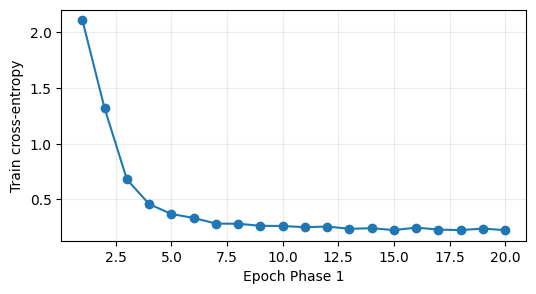

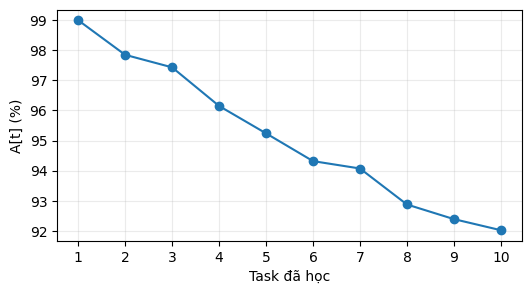

A[10] = 92.02%


In [6]:
import matplotlib.pyplot as plt

rows = result['epochs']
if rows:
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot([row['epoch'] for row in rows], [row['train_loss'] for row in rows], marker='o')
    ax.set(xlabel='Epoch Phase 1', ylabel='Train cross-entropy')
    ax.grid(alpha=0.25)
    plt.show()

rows = result['tasks']
if rows:
    tasks = [row['task'] for row in rows]
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(tasks, [row['avg_accuracy_pct'] for row in rows], marker='o')
    ax.set(xlabel='Task đã học', ylabel='A[t] (%)', xticks=tasks)
    ax.grid(alpha=0.25)
    plt.show()
    if tasks[-1] == 10:
        print(f"A[10] = {rows[-1]['avg_accuracy_pct']:.2f}%")